In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

# Path 
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
data_dir = project_root / "data"

# Load train and test datasets
train_df = pd.read_csv(data_dir / "train_split.csv")
test_df = pd.read_csv(data_dir / "test_split.csv")

print(train_df.shape)
print(test_df.shape)

(84, 25)
(22, 25)


In [8]:
# Group features into engagement vs count/age
engagement_features = [
    "fork_star_ratio",
    "subscriber_star_ratio",
    "issues_per_star",
    "contributor_activity_ratio",
    "ghost_contributor_ratio"
]

volume_age_features = [
    "stargazers_count",
    "forks_count",
    "subscribers_count",
    "open_issues_count",
    "size",
    "age_days",
    "days_since_push",
    "stars_per_day",
    "has_license",
    "is_org_owned"
]

feature_columns = volume_age_features + engagement_features

X_train = train_df[feature_columns].astype(float)
y_train = train_df["target_label"]

X_test = test_df[feature_columns].astype(float)
y_test = test_df["target_label"]

In [19]:
# 1. Individual Signals (Logistic Regression)
single_feature_results = []

for feature in feature_columns:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ])
    pipe.fit(X_train[[feature]], y_train)
    
    train_auc = roc_auc_score(y_train, pipe.predict_proba(X_train[[feature]])[:, 1])
    test_auc = roc_auc_score(y_test, pipe.predict_proba(X_test[[feature]])[:, 1])
    
    single_feature_results.append({
        "Model / Signal": f"Signal: {feature}",
        "Train ROC-AUC": round(train_auc, 4),
        "Test ROC-AUC": round(test_auc, 4),
        "Overfit Diff": round(train_auc - test_auc, 4)
    })

# 2. Combined Logistic Regression Model
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipeline.fit(X_train, y_train)
lr_train_probs = lr_pipeline.predict_proba(X_train)[:, 1]
lr_test_probs = lr_pipeline.predict_proba(X_test)[:, 1]

# 3. Combined Random Forest Model
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=100, max_depth=5, class_weight="balanced", random_state=42))
])
rf_pipeline.fit(X_train, y_train)
rf_train_probs = rf_pipeline.predict_proba(X_train)[:, 1]
rf_test_probs = rf_pipeline.predict_proba(X_test)[:, 1]

# Summary results table
combined_results = [
    {
        "Model / Signal": "Combined: Logistic Regression",
        "Train ROC-AUC": round(roc_auc_score(y_train, lr_train_probs), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, lr_test_probs), 4),
        "Overfit Diff": round(roc_auc_score(y_train, lr_train_probs) - roc_auc_score(y_test, lr_test_probs), 4)
    },
    {
        "Model / Signal": "Combined: Random Forest",
        "Train ROC-AUC": round(roc_auc_score(y_train, rf_train_probs), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, rf_test_probs), 4),
        "Overfit Diff": round(roc_auc_score(y_train, rf_train_probs) - roc_auc_score(y_test, rf_test_probs), 4)
    }
]

df_single = pd.DataFrame(single_feature_results).sort_values(by="Test ROC-AUC", ascending=False)
df_combined = pd.DataFrame(combined_results)

comparison_summary = pd.concat([df_combined, df_single], ignore_index=True)
comparison_summary.to_csv(data_dir / "task3_model_comparison.csv", index=False)

print(comparison_summary.head(8).to_string(index=False))

               Model / Signal  Train ROC-AUC  Test ROC-AUC  Overfit Diff
Combined: Logistic Regression         0.9895        0.9765        0.0130
      Combined: Random Forest         1.0000        0.9765        0.0235
             Signal: age_days         0.9664        0.9882       -0.0218
Signal: subscriber_star_ratio         0.9595        0.9529        0.0066
    Signal: subscribers_count         0.8810        0.9412       -0.0602
    Signal: open_issues_count         0.9016        0.9059       -0.0043
                 Signal: size         0.8939        0.8353        0.0586
        Signal: stars_per_day         0.8032        0.8353       -0.0321


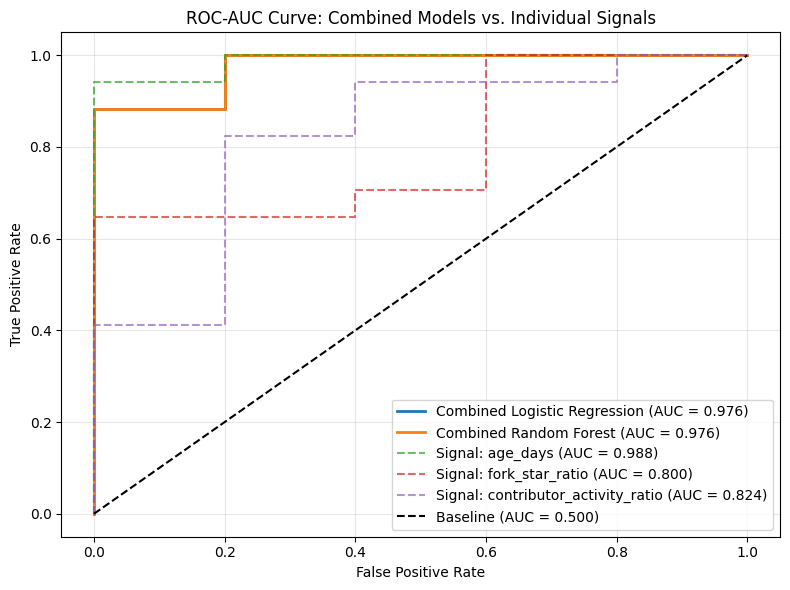

In [ ]:
plt.figure(figsize=(8, 6))

# Plot Combined Models
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_test_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_test_probs)

plt.plot(lr_fpr, lr_tpr, label=f"Combined Logistic Regression (AUC = {roc_auc_score(y_test, lr_test_probs):.3f})", linewidth=2)
plt.plot(rf_fpr, rf_tpr, label=f"Combined Random Forest (AUC = {roc_auc_score(y_test, rf_test_probs):.3f})", linewidth=2)

# Plot Single Features for Comparison
for feature in ["age_days", "fork_star_ratio", "contributor_activity_ratio"]:
    feature_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression())
    ])
    feature_pipe.fit(X_train[[feature]], y_train)
    probs = feature_pipe.predict_proba(X_test[[feature]])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, linestyle="--", alpha=0.7, label=f"Signal: {feature} (AUC = {roc_auc_score(y_test, probs):.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Baseline (AUC = 0.500)')
plt.title('ROC-AUC Curve: Combined Models vs. Individual Signals')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

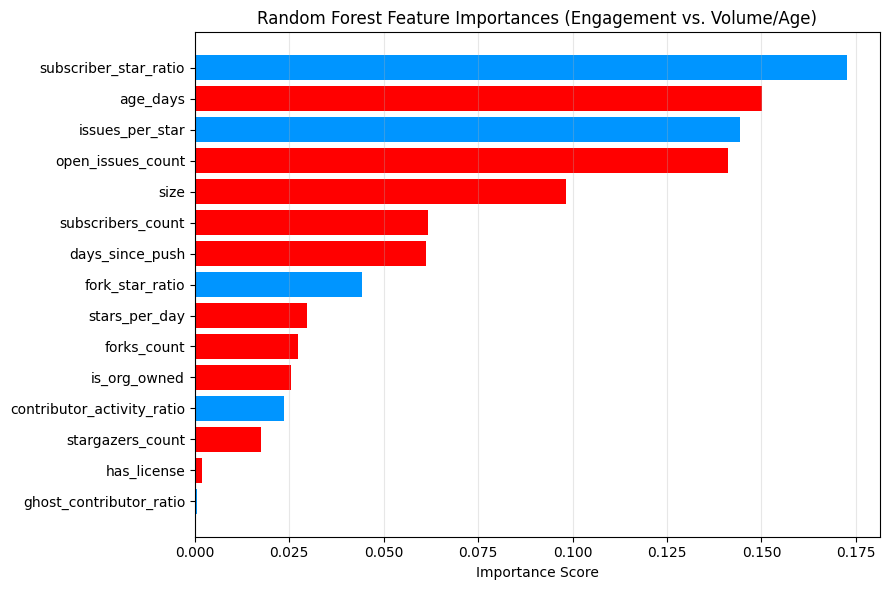

In [28]:
# Get feature importance from Random Forest
rf_model = rf_pipeline.named_steps["model"]
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(9, 6))
colors = ["#0095ff" if feature in engagement_features else "#ff0000" for feature in importance_df["Feature"]]

plt.barh(importance_df["Feature"], importance_df["Importance"], color=colors)
plt.title("Random Forest Feature Importances (Engagement vs. Volume/Age)")
plt.xlabel("Importance Score")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1253/3587899789.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=test_df, x='target_label', y='subscriber_star_ratio', ax=axes[0, 0], palette=["#ff1900", "#0099ff"])
/tmp/ipykernel_1253/3587899789.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Uncertain', 'Good / Legitimate'])
/tmp/ipykernel_1253/3587899789.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=test_df, x='target_label', y='fork_star_ratio', ax=axes[0, 1], palette=["#ff1900", "#00ff6a"])
/tmp/ipykernel_1253/3587899789.py:13: UserWarning: set_ticklabels() should only be used with a 

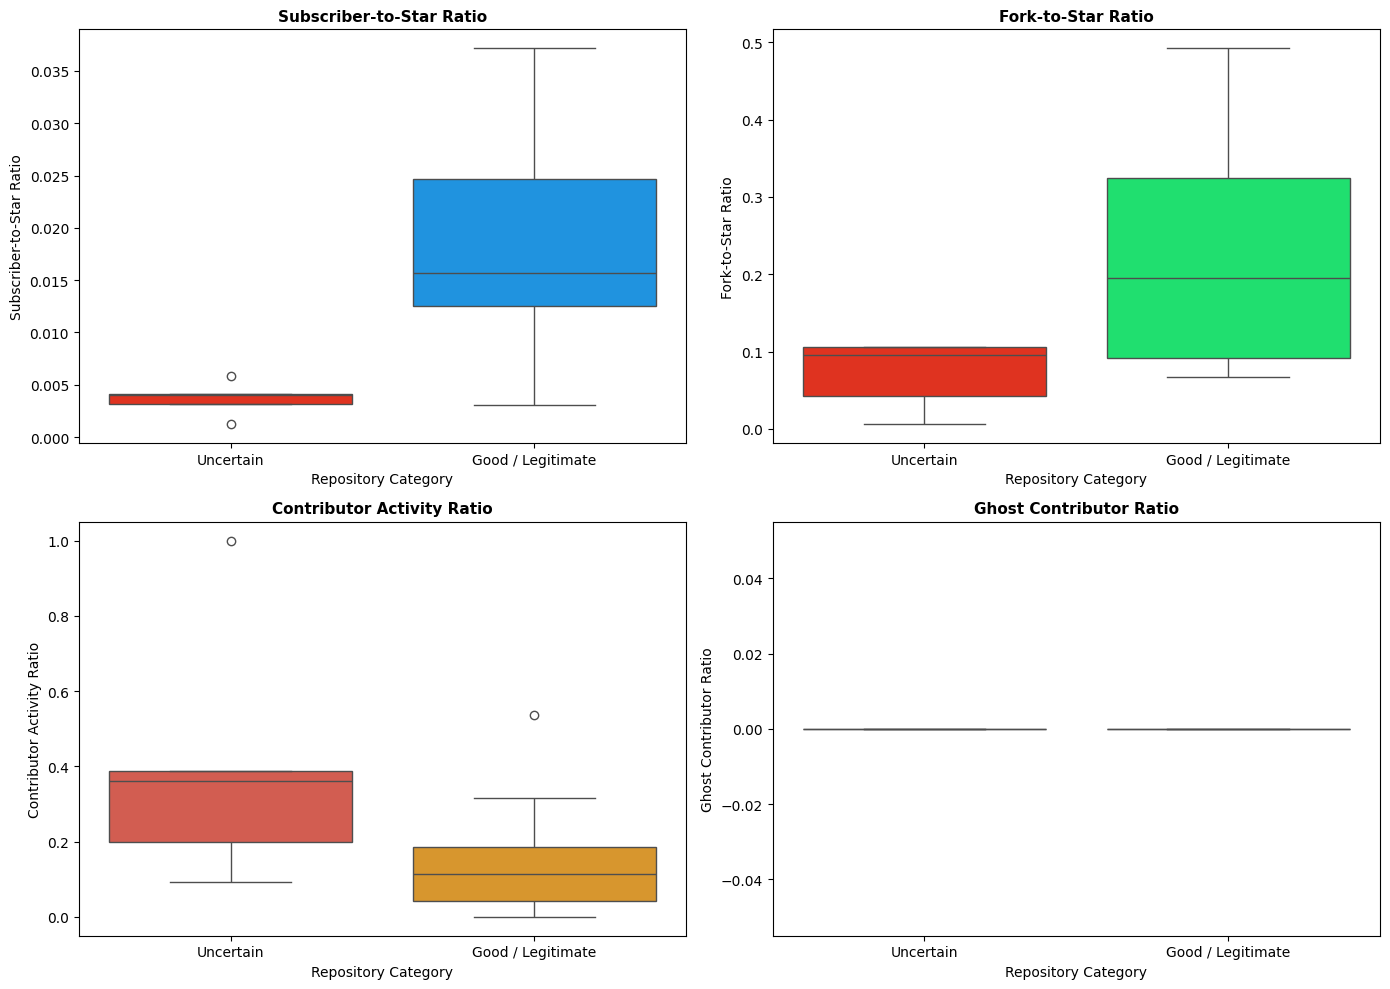

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Subscriber-to-Star Ratio Distribution
sns.boxplot(data=test_df, x='target_label', y='subscriber_star_ratio', ax=axes[0, 0], palette=["#ff1900", "#0099ff"])
axes[0, 0].set_title("Subscriber-to-Star Ratio", fontsize=11, fontweight='bold')
axes[0, 0].set_xticklabels(['Uncertain', 'Good / Legitimate'])
axes[0, 0].set_xlabel('Repository Category')
axes[0, 0].set_ylabel('Subscriber-to-Star Ratio')

# 2. Fork-to-Star Ratio Distribution
sns.boxplot(data=test_df, x='target_label', y='fork_star_ratio', ax=axes[0, 1], palette=["#ff1900", "#00ff6a"])
axes[0, 1].set_title("Fork-to-Star Ratio", fontsize=11, fontweight='bold')
axes[0, 1].set_xticklabels(['Uncertain', 'Good / Legitimate'])
axes[0, 1].set_xlabel('Repository Category')
axes[0, 1].set_ylabel('Fork-to-Star Ratio')

# 3. Contributor Activity Ratio
sns.boxplot(data=test_df, x='target_label', y='contributor_activity_ratio', ax=axes[1, 0], palette=['#e74c3c', '#f39c12'])
axes[1, 0].set_title("Contributor Activity Ratio", fontsize=11, fontweight='bold')
axes[1, 0].set_xticklabels(['Uncertain', 'Good / Legitimate'])
axes[1, 0].set_xlabel('Repository Category')
axes[1, 0].set_ylabel('Contributor Activity Ratio')

# 4. Ghost Contributor Ratio
sns.boxplot(data=test_df, x='target_label', y='ghost_contributor_ratio', ax=axes[1, 1], palette=["#ff1900", '#9b59b6'])
axes[1, 1].set_title("Ghost Contributor Ratio", fontsize=11, fontweight='bold')
axes[1, 1].set_xticklabels(['Uncertain', 'Good / Legitimate'])
axes[1, 1].set_xlabel('Repository Category')
axes[1, 1].set_ylabel('Ghost Contributor Ratio')

plt.tight_layout()
plt.show()

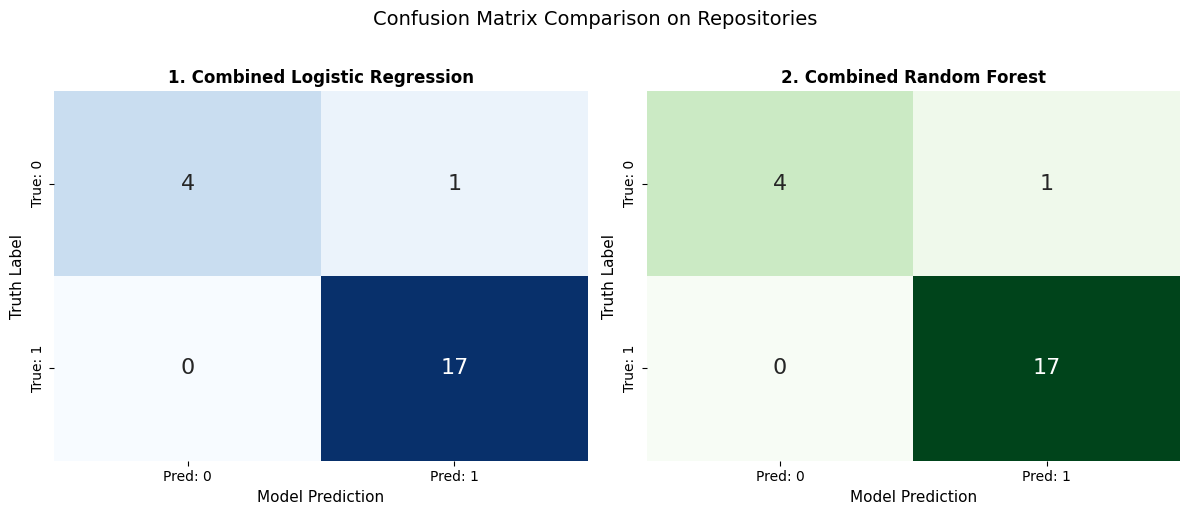

In [36]:
# Predictions at 0.50 threshold
lr_predictions = (lr_test_probs >= 0.50).astype(int)
rf_predictions = (rf_test_probs >= 0.50).astype(int)

# Calculate confusion matrices
cm_lr = confusion_matrix(y_test, lr_predictions)
cm_rf = confusion_matrix(y_test, rf_predictions)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Logistic Regression Matrix
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['True: 0', 'True: 1'], annot_kws={"size": 16})
axes[0].set_title("1. Combined Logistic Regression", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Truth Label", fontsize=11)
axes[0].set_xlabel("Model Prediction", fontsize=11)

# Plot 2: Random Forest Matrix
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False,
            xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['True: 0', 'True: 1'], annot_kws={"size": 16})
axes[1].set_title("2. Combined Random Forest", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Truth Label", fontsize=11)
axes[1].set_xlabel("Model Prediction", fontsize=11)

plt.suptitle("Confusion Matrix Comparison on Repositories", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()